# 27. Куда уходят байты

[Программа курса](../../README_ru.md)

Скульптура из урока 20 помещается в маленький файл. Ноутбук открывает её, создаёт картинку, а при обучении держит рядом ещё несколько массивов. В диспетчере задач получится совсем другое число. Начнём с одного пятна, которое можно пересчитать по пальцам.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "compression_math.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import compression_math as codec
import compression_demos as demos
from reconstruction import scores, benchmark
from splat_render import render_scene, orbit_camera
lang = "ru"

## Сначала одно пятно

У центра три координаты в метрах. У формы три положительные ширины в метрах. Ориентация задана четырьмя компонентами кватерниона, у цвета три канала в диапазоне от 0 до 1, у непрозрачности ещё одно число в том же диапазоне. Получается $3+3+4+3+1=14$ чисел. Представление float32 отводит каждому числу 32 бита. В байте 8 бит, значит $32/8=4$ байта. На одно пятно уйдёт $14\cdot4=56$ байт.

У скульптуры 117 пятен. Одни центры займут $117\cdot3\cdot4=1404$ байта. Полезные числа всей сцены — $117\cdot56=6552$ байта. Двоичный пакет добавит заголовок. Текст JSON ещё хранит названия полей, скобки и цифры десятичной записи. Следующая ячейка действительно читает файл и собирает пакет.

In [2]:
scene, frames = codec.photo_data()
packet = codec.pack_static(scene, 'f32')
print('JSON, bytes:', (codec.ASSETS / 'photo-reference.json').stat().st_size)
print('GSC1, bytes:', len(packet), '= 8 +', len(packet)-8)
print('float32 parameters:', np.empty((117, 14), dtype=np.float32).nbytes)

JSON, bytes: 39038
GSC1, bytes: 6560 = 8 + 6552
float32 parameters: 6552


## Когда красный зависит от ракурса

У постоянного RGB на каждый канал приходится одно число. В разложении цвета по сферическим гармоникам порядок $L$ — целое число от нуля. У каждого следующего порядка на две функции больше. При $L=0$ есть одна функция, при $L=1$ добавятся три, при $L=2$ ещё пять. При $L=3$ помещаются $1+3+5+7=16$ функций, каждая со своим коэффициентом на канал. У трёх каналов $3\cdot16=48$ коэффициентов. Такой набор занимает больше места ещё до того, как появился хоть один пиксель.

Для одного пятна сумма нечётных чисел равна $(L+1)^2$. Например, $L=3$ даёт $(3+1)^2=4\cdot4=16$. Обозначим число пятен через $N$. Кроме цвета на каждое приходится $3+3+4+1=11$ чисел. Память параметров в **байтах** получится такой:

$$
B=4N\left(11+3(L+1)^2\right).
$$

При 117 пятнах и третьем порядке это $4\cdot117\cdot(11+48)=27612$ байт. Ползунок порядка меняет предполагаемую раскладку. У загруженной скульптуры по-прежнему постоянный RGB.

In [3]:
display(demos.codec_lab(27, lang))

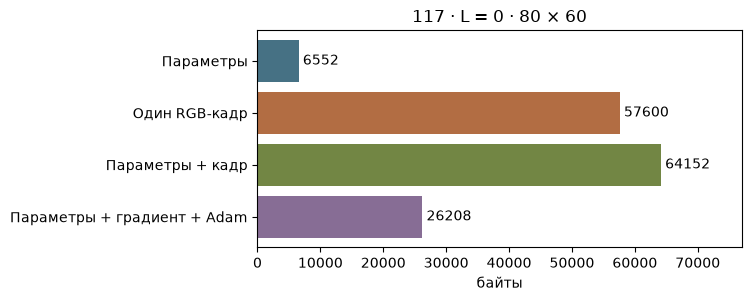

In [4]:
demos.storage_figure(lang, count=117, degree=0, width=80)
plt.show()

## Экран тоже просит память

Картинка шириной 80 и высотой 60 содержит $80\cdot60=4800$ пикселей. Три канала float32 дают $4800\cdot3\cdot4=57600$ байт. Вместе с параметрами скульптуры получается $57600+6552=64152$ байта. В нижней строке опыта высота равна трём четвертям ширины с округлением до ближайшего пикселя. При удвоении обеих сторон число пикселей увеличится в четыре раза.

Пока это заданная раскладка плотных массивов. Учебный рендерер в действительности возвращает RGB в float64, то есть 8 байт на канал. Ячейка измеряет только сами элементы массива через `nbytes`. В работе ещё живут объекты Python, промежуточные массивы, проекции и память библиотек. В реализации на GPU добавятся списки тайлов и рабочая память устройства. По размеру файла их определить нельзя.

(60, 80, 3) float64 115200
float32 copy: 57600


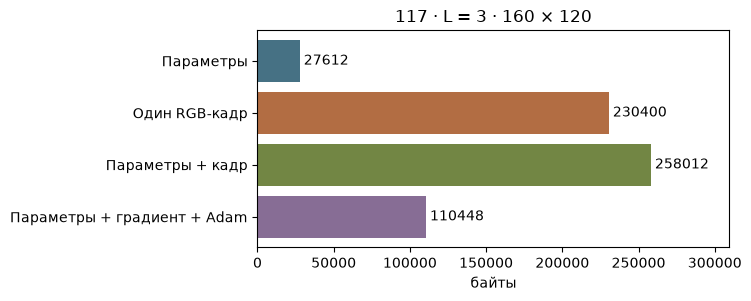

In [5]:
img = render_scene(scene, frames['view-04.jpg']['camera'], 80, 60)
print(img.shape, img.dtype, img.nbytes)
print('float32 copy:', img.astype(np.float32).nbytes)
demos.storage_figure(lang, count=117, degree=3, width=160)
plt.show()

## Что меняется при обучении

Для простого расчёта все 14 параметров обучаются в float32. Градиент занимает ещё один массив той же формы. Adam запоминает среднее прошлых градиентов и среднее их квадратов — два массива. Итого четыре комплекта одинакового размера. На скульптуру приходится $4\cdot6552=26208$ байт **для этих четырёх массивов**. Остальные затраты зависят от реализации, числа видимых пятен и того, что осталось в памяти для обратного прохода. В просмотрщике сохранённой сцены ни градиенты, ни эти два средних уже не нужны.

**Опыт.** Что будет дороже для 117 пятен — поднять порядок цвета с нуля до трёх или добавить ещё один RGB-кадр 80 × 60 в float32?

<details>
<summary>Разбор</summary>

Прирост параметров $27612-6552=21060$ байт. У кадра 57600 байт. Значит, второй буфер требует на $57600-21060=36540$ байт больше. При миллионе пятен соотношение изменится, потому что память кадра осталась прежней.

</details>